# RSNA Knee Abnormality Detection — Dataset & DICOM Exploration

This notebook performs a structured first-pass audit of the **RSNA Knee Abnormality Detection** Kaggle competition dataset.

## Goals
1. Load and verify all CSV files.
2. Understand the **study → series → DICOM slices** hierarchy.
3. Audit the 12 target labels and gold-label availability.
4. Analyze MRI series metadata (plane, fluid sensitivity, fat suppression).
5. Select one fully labeled study.
6. Inspect its report, labels, DICOM folders, metadata, geometry, and representative images.
7. Build robust slice-ordering helpers.
8. Produce a QC summary before modeling.

> No model training is performed here. The purpose is to understand the data correctly first.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 180)

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]
print("Imports loaded successfully.")

Imports loaded successfully.


## 2. Locate the Kaggle dataset automatically

In [2]:
CANDIDATES = [
    Path("/kaggle/input/competitions/rsna-knee-abnormality-detection"),
    Path("/kaggle/input/rsna-knee-abnormality-detection"),
]
DATA_DIR = next((p for p in CANDIDATES if p.exists()), None)

if DATA_DIR is None:
    matches = [p for p in Path("/kaggle/input").rglob("*")
               if p.is_dir() and p.name == "rsna-knee-abnormality-detection"]
    DATA_DIR = matches[0] if matches else None

if DATA_DIR is None:
    raise FileNotFoundError("Attach the RSNA competition data to this Kaggle notebook first.")

print("DATA_DIR =", DATA_DIR)
print("\nTop-level contents:")
for p in sorted(DATA_DIR.iterdir()):
    print(" -", p.name)

DATA_DIR = /kaggle/input/competitions/rsna-knee-abnormality-detection

Top-level contents:
 - sample_submission.csv
 - test.csv
 - test_series
 - test_series.csv
 - train.csv
 - train_series
 - train_series.csv


## 3. Load CSV files

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
train_series = pd.read_csv(DATA_DIR / "train_series.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
test_series = pd.read_csv(DATA_DIR / "test_series.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

datasets = {
    "train": train,
    "train_series": train_series,
    "test": test,
    "test_series": test_series,
    "sample_submission": sample_submission,
}
print("All CSV files loaded.")

All CSV files loaded.


## 4. Dataset structure

In [4]:
for name, df in datasets.items():
    print("\n" + "=" * 90)
    print(name.upper())
    print("=" * 90)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())


TRAIN
Shape: (4407, 14)
Columns: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. ....,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585,[DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gewogen seq zonder ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231,Hallazgos:\nNo hay alteraciones en significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límites normales.\nAumento de señal del cuerno posterior del m...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764,"In the medial compartment, the meniscus is not torn and there is no focal chondrosis or chondral injury. \n The lateral compartment, there is suspicious incomplete discoid lat...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029415768216599146542,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAlignement articulaire :\nNormal.\n\nChangements dégénératifs :\nChondropatie rétropatellaire modérée à sévère avec fissuration profo...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



TRAIN_SERIES
Shape: (24371, 5)
Columns: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,1.2.826.0.1.3680043.8.498.75714899997203615784077798038670363546,0,0,Sagittal



TEST
Shape: (3, 1)
Columns: ['StudyInstanceUID']


,StudyInstanceUID
0,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
1,1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
2,1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402



TEST_SERIES
Shape: (15, 5)
Columns: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,1.2.826.0.1.3680043.8.498.11580656442259111255675562605155903947,0,0,Axial
1,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,1.2.826.0.1.3680043.8.498.17811502614030631664517622518906646132,0,0,Sagittal
2,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,1.2.826.0.1.3680043.8.498.30565395595045942404081022062489758495,0,0,Sagittal
3,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,1.2.826.0.1.3680043.8.498.32856494541816845805947850304653662081,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,1.2.826.0.1.3680043.8.498.44334485654554877495800965096767429689,1,1,Axial



SAMPLE_SUBMISSION
Shape: (3, 13)
Columns: ['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
1,1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
2,1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5


## 5. Missing-value audit

In [5]:
for name, df in datasets.items():
    print("\n" + "=" * 90)
    print(name.upper())
    print("=" * 90)
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    if len(missing):
        display(missing.to_frame("Missing"))
    else:
        print("No missing values.")

print("\nTraining studies:", len(train))
print("Test studies:", len(test))
print("Training series:", len(train_series))
print("Test series:", len(test_series))


TRAIN


,Missing
ACL,4349
MCL,4349
Medial Meniscus,4349
Lateral Meniscus,4349
Medial OA,4349
Lateral OA,4349
PF OA,4349
Effusion,4349
Synovitis,4349
Baker's,4349



TRAIN_SERIES
No missing values.

TEST
No missing values.

TEST_SERIES
No missing values.

SAMPLE_SUBMISSION
No missing values.

Training studies: 4407
Test studies: 3
Training series: 24371
Test series: 15


# 6. Gold-label audit

This checks whether studies are fully labeled, partially labeled, or completely unlabeled.

In [6]:
train = train.copy()
train["n_labels_available"] = train[TARGETS].notna().sum(axis=1)

display(train["n_labels_available"].value_counts().sort_index().to_frame("Study count"))

n_full = (train["n_labels_available"] == len(TARGETS)).sum()
n_zero = (train["n_labels_available"] == 0).sum()
n_partial = ((train["n_labels_available"] > 0) &
             (train["n_labels_available"] < len(TARGETS))).sum()

print("Fully labeled studies:    ", n_full)
print("Completely unlabeled:     ", n_zero)
print("Partially labeled studies:", n_partial)
print(f"Gold-labeled fraction: {100*n_full/len(train):.2f}%")

,Study count
n_labels_available,
0,4349
12,58


Fully labeled studies:     58
Completely unlabeled:      4349
Partially labeled studies: 0
Gold-labeled fraction: 1.32%


## 7. Fully labeled subset and target values

In [7]:
labeled = train[train["n_labels_available"] == len(TARGETS)].copy()
print("Fully labeled studies:", len(labeled))
display(labeled[["StudyInstanceUID", "Report"] + TARGETS].head())

print("\nTarget values:")
for target in TARGETS:
    print(f"{target:20s} -> {sorted(labeled[target].dropna().unique().tolist())}")

Fully labeled studies: 58


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,Antecedentes Clínicos:\nEsguince rodilla. [DATE].\nHallazgos:\nNo hay alteraciones de señal significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límit...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028696505248839028269,The study reveals normal knee joint alignment. No fracture is seen. \n ACL is intact. PCL is preserved. \n The MCL is intact. Medial meniscus is not torn. \n The...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538703788080836752052,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Date and Time: [DATE] [TIME]\nIndication: 2 years of pain with walking up and down the stairs twisting and squatting.\nComparison: N...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,1.2.826.0.1.3680043.8.498.11287937729196958426538087439102017580,"MRI of left Knee with \n-3-Plane Loc R'T, Sag PD FS, AX T2 FS, Sag T2 FS, Sag T1, CORT2 FS\n\n> There is no abnormal intensity or articular surface disrupt in the medial menisc...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.2.826.0.1.3680043.8.498.11382021393803389951964005983002209238,"In the medial compartment, there is longitudinal vertical tear at the body and posterior horn of the medial meniscus. There is no focal chondrosis or chondral injury. \n The l...",1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Target values:
ACL                  -> [0.0, 1.0]
MCL                  -> [0.0, 1.0]
Medial Meniscus      -> [0.0, 1.0]
Lateral Meniscus     -> [0.0, 1.0]
Medial OA            -> [0.0, 1.0]
Lateral OA           -> [0.0, 1.0]
PF OA                -> [0.0, 1.0]
Effusion             -> [0.0, 1.0]
Synovitis            -> [0.0, 1.0]
Baker's              -> [0.0, 1.0]
Contusion            -> [0.0, 1.0]
Fracture             -> [0.0, 1.0]


## 8. Target distribution in the gold subset

These percentages describe only the small labeled subset and should **not** be interpreted as population prevalence.

In [8]:
rows=[]
for target in TARGETS:
    valid = labeled[target].dropna()
    pos = int((valid == 1).sum())
    neg = int((valid == 0).sum())
    rows.append({
        "Target": target,
        "Available": len(valid),
        "Positive": pos,
        "Negative": neg,
        "Positive %": 100*pos/len(valid) if len(valid) else np.nan,
    })
label_summary = pd.DataFrame(rows)
display(label_summary)

,Target,Available,Positive,Negative,Positive %
0,ACL,58,24,34,41.379310
1,MCL,58,9,49,15.517241
2,Medial Meniscus,58,26,32,44.827586
3,Lateral Meniscus,58,23,35,39.655172
4,Medial OA,58,15,43,25.862069
5,Lateral OA,58,11,47,18.965517
6,PF OA,58,21,37,36.206897
7,Effusion,58,35,23,60.344828
8,Synovitis,58,27,31,46.551724
9,Baker's,58,12,46,20.689655


## 9. Report availability and text-length statistics

In [9]:
print("Missing reports:", train["Report"].isna().sum())
print("Non-missing reports:", train["Report"].notna().sum())

report_lengths = train["Report"].fillna("").str.len()
display(report_lengths.describe().to_frame("characters"))

print("\nFirst five report excerpts:")
for idx in train.index[:5]:
    print("\n" + "=" * 90)
    print("Index:", idx)
    print(str(train.loc[idx, "Report"])[:1200])

Missing reports: 0
Non-missing reports: 4407


,characters
count,4407.000000
mean,1097.905605
std,693.948925
min,52.000000
25%,587.500000
50%,977.000000
75%,1459.500000
max,4743.000000



First five report excerpts:

Index: 0
Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.

Index: 1
[DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gewogen seq zonder en met fs, ax/ cor pd gewogen seq fs, cor T1 gewogen seq Bevindingen:

Index: 2
Hallazgos:
No hay alteraciones en significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Aumento de señal del cuerno posterior del menisco medial que no impresiona contactar con la
superficie articular, sin caracteres propios de rotura.
Menisco lateral de morfología y señal conservada, sin signos de rotura.
Úlceras condrales de e

# 10. Study → series relationship

- `train.csv`: one row per MRI **study**.
- `train_series.csv`: one row per MRI **series**.
- Each study can contain several series.

In [10]:
series_per_study = train_series.groupby("StudyInstanceUID").size().rename("n_series")
print("Series per study:")
display(series_per_study.describe().to_frame())
print("Average:", round(series_per_study.mean(), 3))

print("\nMost common series counts:")
display(series_per_study.value_counts().sort_index().to_frame("Number of studies").head(20))

Series per study:


,n_series
count,4407.000000
mean,5.530066
std,1.393826
min,3.000000
25%,5.000000
50%,5.000000
75%,6.000000
max,14.000000


Average: 5.53

Most common series counts:


,Number of studies
n_series,
3,1
4,675
5,2299
6,698
7,310
8,145
9,176
10,74
11,21


## 11. MRI series metadata distributions

In [11]:
print("Anatomical planes:")
display(train_series["Anatomical_Plane"].value_counts(dropna=False).to_frame("Series count"))

print("\nFluid-sensitive:")
display(train_series["Fluid_Sensitive"].value_counts(dropna=False).sort_index().to_frame("Series count"))

print("\nFat suppression:")
display(train_series["Fat_Suppression"].value_counts(dropna=False).sort_index().to_frame("Series count"))

print("\nPlane × Fluid × Fat-suppression combinations:")
combo = (train_series.groupby(["Anatomical_Plane", "Fluid_Sensitive", "Fat_Suppression"])
         .size().rename("Series count").reset_index()
         .sort_values("Series count", ascending=False))
display(combo)

Anatomical planes:


,Series count
Anatomical_Plane,
Sagittal,9864
Coronal,8609
Axial,5898



Fluid-sensitive:


,Series count
Fluid_Sensitive,
0,10361
1,14010



Fat suppression:


,Series count
Fat_Suppression,
0,10361
1,14010



Plane × Fluid × Fat-suppression combinations:


,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,Series count
4,Sagittal,0,0,5197
1,Axial,1,1,4719
5,Sagittal,1,1,4667
3,Coronal,1,1,4624
2,Coronal,0,0,3985
0,Axial,0,0,1179


## 12. Study/series metadata consistency

In [12]:
train_ids = set(train["StudyInstanceUID"].astype(str))
series_ids = set(train_series["StudyInstanceUID"].astype(str))
print("Train studies missing from train_series.csv:", len(train_ids - series_ids))
print("Series metadata with no matching train.csv study:", len(series_ids - train_ids))

Train studies missing from train_series.csv: 0
Series metadata with no matching train.csv study: 0


# 13. Select one fully labeled study

Default: dataframe index **29**, the labeled case already inspected. Change `STUDY_INDEX` later to inspect another gold case.

In [13]:
STUDY_INDEX = 29
if STUDY_INDEX not in labeled.index:
    STUDY_INDEX = labeled.index[0]

study_row = train.loc[STUDY_INDEX]
study_uid = str(study_row["StudyInstanceUID"])

print("Selected dataframe index:", STUDY_INDEX)
print("StudyInstanceUID:")
print(study_uid)

Selected dataframe index: 29
StudyInstanceUID:
1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149


## 14. Selected study — radiology report

In [14]:
print("=" * 100)
print("RADIOLOGY REPORT")
print("=" * 100)
print(study_row["Report"])

RADIOLOGY REPORT
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del
tendón rotuliano, sin signos de rotura.
No hay alteraciones de señal de la grasa de Hoffa.
Impresión:
Amputación marginal del cuerpo del menisco lateral.
Condropatía focal grado 4 del aspect

## 15. Selected study — official labels

In [15]:
study_labels = study_row[TARGETS].astype(float).to_frame("Label")
display(study_labels)
positive_labels = study_labels.index[study_labels["Label"] == 1].tolist()
negative_labels = study_labels.index[study_labels["Label"] == 0].tolist()
print("Positive labels:", positive_labels)
print("Negative labels:", negative_labels)

,Label
ACL,0.0
MCL,0.0
Medial Meniscus,0.0
Lateral Meniscus,0.0
Medial OA,0.0
Lateral OA,0.0
PF OA,1.0
Effusion,1.0
Synovitis,0.0
Baker's,0.0


Positive labels: ['PF OA', 'Effusion']
Negative labels: ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


## 16. Selected study — series metadata

In [16]:
study_series = (train_series[train_series["StudyInstanceUID"].astype(str) == study_uid]
                .copy().reset_index(drop=True))
print("Number of MRI series:", len(study_series))
display(study_series)

Number of MRI series: 5


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282,0,0,Sagittal
1,1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441,0,0,Coronal
2,1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198,1,1,Coronal
3,1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429,1,1,Sagittal
4,1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430,1,1,Axial


# 17. Locate DICOM folders

Expected hierarchy:

```text
train_series/
└── StudyInstanceUID/
    ├── SeriesInstanceUID/
    │   ├── DICOM slice
    │   ├── DICOM slice
    │   └── ...
    └── ...
```

In [17]:
TRAIN_IMAGE_DIR = DATA_DIR / "train_series"
study_path = TRAIN_IMAGE_DIR / study_uid
print("Study folder:", study_path)
print("Exists:", study_path.exists())

if not study_path.exists():
    raise FileNotFoundError(study_path)

series_folders = [p for p in study_path.iterdir() if p.is_dir()]
print("Series folders found:", len(series_folders))
for p in sorted(series_folders):
    print(" -", p.name)

Study folder: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Exists: True
Series folders found: 5
 - 1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282
 - 1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441
 - 1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198
 - 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
 - 1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430


# 18. DICOM helper functions

For anatomical slice ordering, prefer spatial DICOM metadata over filename order:

1. `ImageOrientationPatient`
2. `ImagePositionPatient`
3. Compute slice normal = row direction × column direction
4. Project slice position onto that normal
5. Fall back to `InstanceNumber` if needed

In [18]:
def get_dicom_files(series_path):
    return [p for p in Path(series_path).iterdir() if p.is_file()]


def safe_float_list(value):
    if value is None:
        return None
    try:
        return [float(x) for x in value]
    except Exception:
        return None


def slice_position_from_header(ds):
    try:
        orientation = np.asarray([float(x) for x in ds.ImageOrientationPatient], dtype=np.float64)
        position = np.asarray([float(x) for x in ds.ImagePositionPatient], dtype=np.float64)
        row_dir = orientation[:3]
        col_dir = orientation[3:]
        normal = np.cross(row_dir, col_dir)
        return float(np.dot(position, normal))
    except Exception:
        return None


def dicom_sort_key(path):
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
        pos = slice_position_from_header(ds)
        if pos is not None:
            return (0, pos)
        instance = getattr(ds, "InstanceNumber", None)
        if instance is not None:
            return (1, float(instance))
    except Exception:
        pass
    return (2, str(path.name))


def sorted_dicom_files(series_path):
    return sorted(get_dicom_files(series_path), key=dicom_sort_key)


def normalize_for_display(img):
    img = np.asarray(img, dtype=np.float32)
    finite = np.isfinite(img)
    if not finite.any():
        return np.zeros_like(img, dtype=np.float32)
    vals = img[finite]
    low, high = np.percentile(vals, [1, 99])
    if high <= low:
        return np.zeros_like(img, dtype=np.float32)
    return (np.clip(img, low, high) - low) / (high - low)


def load_dicom_pixels(path):
    ds = pydicom.dcmread(str(path))
    img = ds.pixel_array.astype(np.float32)
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    img = img * slope + intercept
    if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
        img = img.max() - img
    return img, ds

## 19. Series-level DICOM metadata summary

In [19]:
rows=[]
for _, row in study_series.iterrows():
    series_uid = str(row["SeriesInstanceUID"])
    series_path = study_path / series_uid
    files = sorted_dicom_files(series_path)

    if not files:
        rows.append({"SeriesInstanceUID": series_uid, "Plane": row["Anatomical_Plane"], "Slices": 0})
        continue

    ds = pydicom.dcmread(str(files[0]), stop_before_pixels=True)
    rows.append({
        "SeriesInstanceUID": series_uid,
        "Plane": row["Anatomical_Plane"],
        "FluidSensitive": int(row["Fluid_Sensitive"]),
        "FatSuppression": int(row["Fat_Suppression"]),
        "Slices": len(files),
        "Rows": getattr(ds, "Rows", None),
        "Columns": getattr(ds, "Columns", None),
        "PixelSpacing": safe_float_list(getattr(ds, "PixelSpacing", None)),
        "SliceThickness": getattr(ds, "SliceThickness", None),
        "SpacingBetweenSlices": getattr(ds, "SpacingBetweenSlices", None),
        "Manufacturer": getattr(ds, "Manufacturer", None),
        "MagneticFieldStrength": getattr(ds, "MagneticFieldStrength", None),
        "RepetitionTime": getattr(ds, "RepetitionTime", None),
        "EchoTime": getattr(ds, "EchoTime", None),
        "FlipAngle": getattr(ds, "FlipAngle", None),
    })

series_summary = pd.DataFrame(rows)
display(series_summary)

,SeriesInstanceUID,Plane,FluidSensitive,FatSuppression,Slices,Rows,Columns,PixelSpacing,SliceThickness,SpacingBetweenSlices,Manufacturer,MagneticFieldStrength,RepetitionTime,EchoTime,FlipAngle
0,1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282,Sagittal,0,0,36,400,400,"[0.4, 0.4]",2.5,2.875,Siemens Healthineers,1.5,6570.0,75.0,150.0
1,1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441,Coronal,0,0,30,384,384,"[0.390625, 0.390625]",3.0,3.450,Siemens Healthineers,1.5,700.0,12.0,160.0
2,1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198,Coronal,1,1,30,320,320,"[0.5, 0.5]",3.0,3.450,Siemens Healthineers,1.5,3980.0,40.0,150.0
3,1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429,Sagittal,1,1,36,320,320,"[0.5, 0.5]",2.5,2.875,Siemens Healthineers,1.5,4790.0,40.0,150.0
4,1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430,Axial,1,1,32,320,320,"[0.5, 0.5]",3.5,4.025,Siemens Healthineers,1.5,4240.0,40.0,150.0


## 20. Slice-position and ordering QC

In [20]:
for _, row in study_series.iterrows():
    series_uid = str(row["SeriesInstanceUID"])
    files = sorted_dicom_files(study_path / series_uid)
    positions=[]
    instances=[]
    for f in files:
        ds = pydicom.dcmread(str(f), stop_before_pixels=True)
        positions.append(slice_position_from_header(ds))
        instances.append(getattr(ds, "InstanceNumber", None))

    valid_positions = [x for x in positions if x is not None]
    print("\n" + "="*100)
    print(row["Anatomical_Plane"], "| Fluid =", row["Fluid_Sensitive"], "| FatSupp =", row["Fat_Suppression"])
    print("Series:", series_uid)
    print("Slices:", len(files))
    print("Spatial positions available:", len(valid_positions), "/", len(files))
    if valid_positions:
        print("Position range:", round(min(valid_positions),4), "to", round(max(valid_positions),4))
    print("First 10 InstanceNumbers:", instances[:10])


Sagittal | Fluid = 0 | FatSupp = 0
Series: 1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282
Slices: 36
Spatial positions available: 36 / 36
Position range: 64.1653 to 164.7901
First 10 InstanceNumbers: ['36', '35', '34', '33', '32', '31', '30', '29', '28', '27']

Coronal | Fluid = 0 | FatSupp = 0
Series: 1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441
Slices: 30
Spatial positions available: 30 / 30
Position range: -110.1792 to -10.1293
First 10 InstanceNumbers: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']

Coronal | Fluid = 1 | FatSupp = 1
Series: 1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198
Slices: 30
Spatial positions available: 30 / 30
Position range: -110.1795 to -10.1293
First 10 InstanceNumbers: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']

Sagittal | Fluid = 1 | FatSupp = 1
Series: 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
Slices: 36
Spatial positions available: 36 / 36
Position range: 64.

# 21. Visualize the middle slice of every series

Normalization here is only for display; original DICOM intensities are not modified on disk.

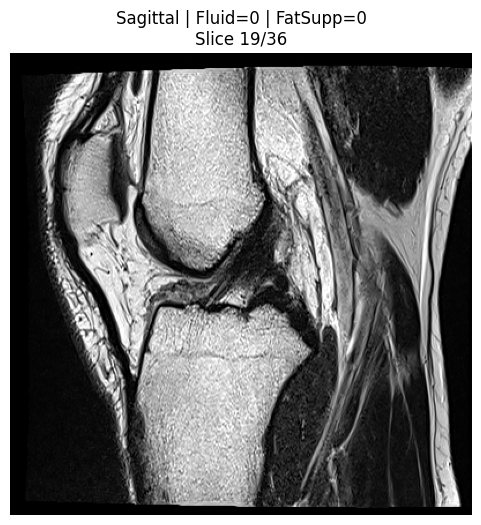

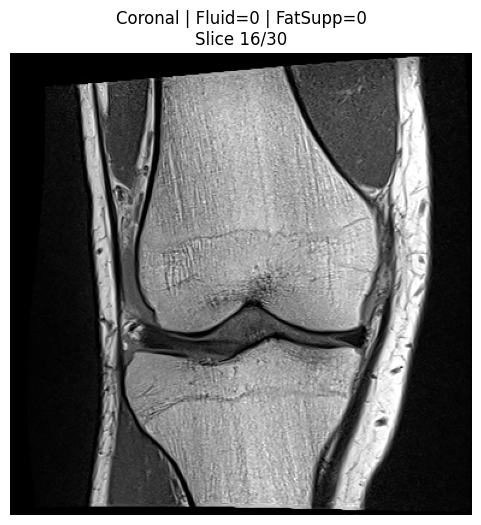

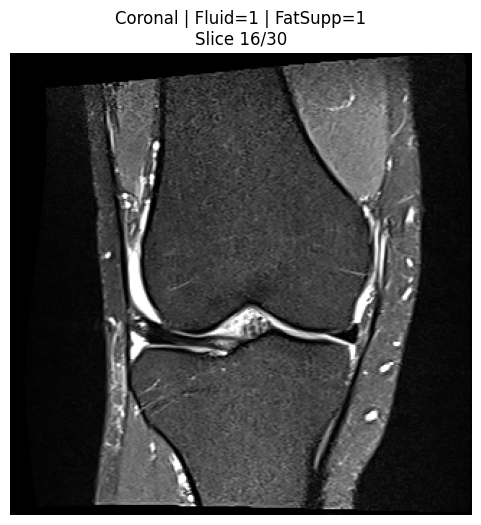

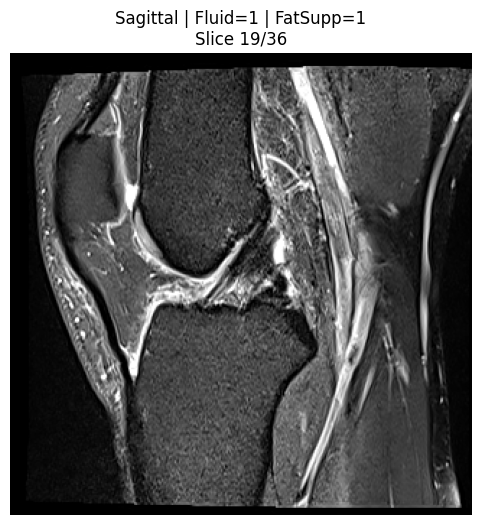

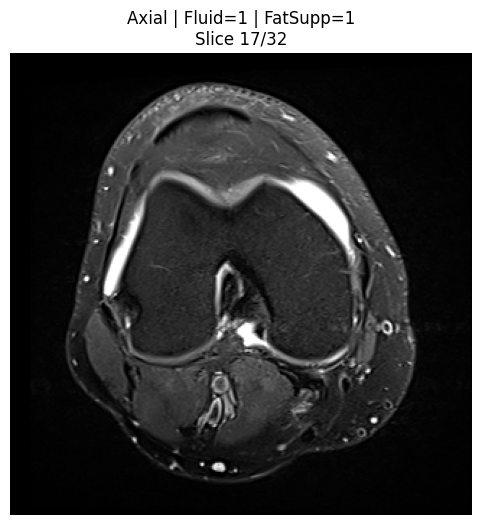

In [21]:
for _, row in study_series.iterrows():
    series_uid = str(row["SeriesInstanceUID"])
    files = sorted_dicom_files(study_path / series_uid)
    if not files:
        continue

    mid = len(files)//2
    img, _ = load_dicom_pixels(files[mid])
    img = normalize_for_display(img)

    plt.figure(figsize=(6,6))
    plt.imshow(img, cmap="gray")
    plt.axis("off")
    plt.title(f'{row["Anatomical_Plane"]} | Fluid={row["Fluid_Sensitive"]} | FatSupp={row["Fat_Suppression"]}\nSlice {mid+1}/{len(files)}')
    plt.show()

# 22. Visualize first, middle, and last slice from each series

Each series is shown as one horizontal strip: **first | middle | last**.

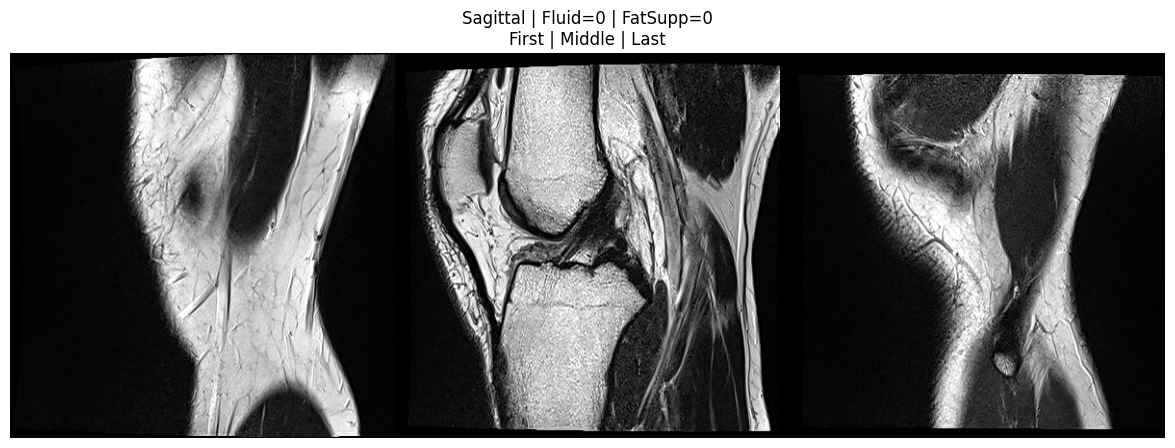

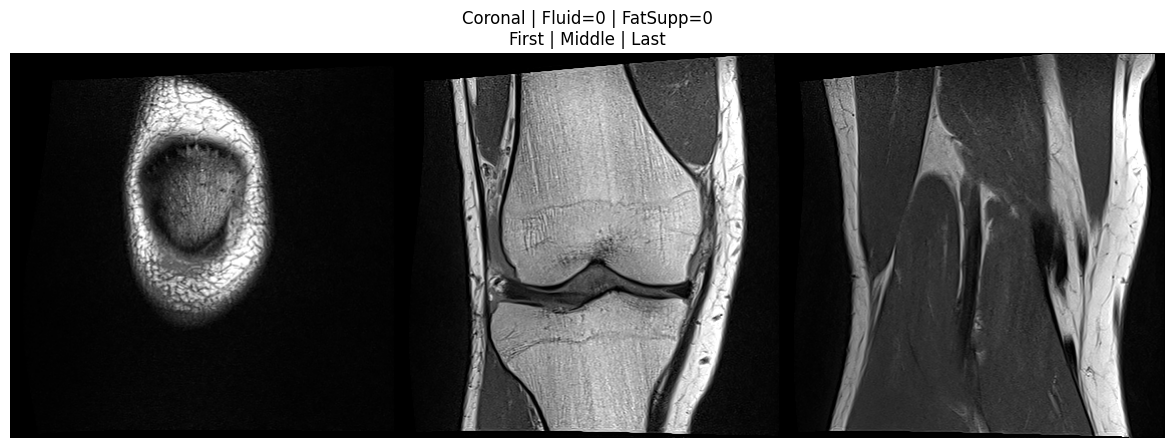

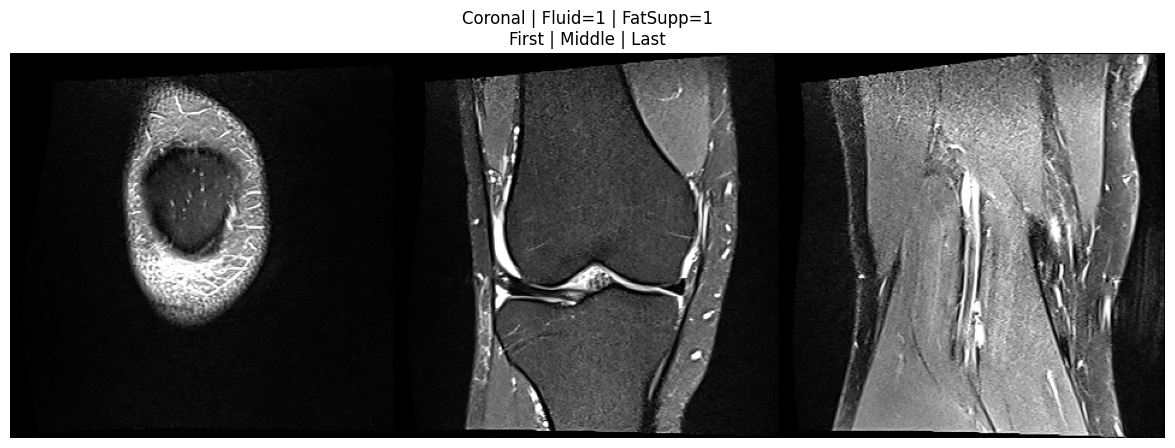

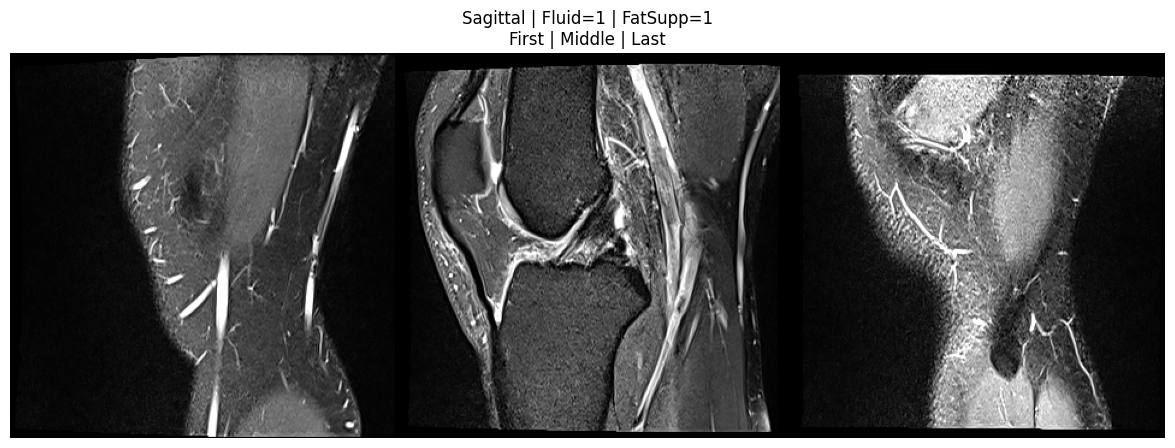

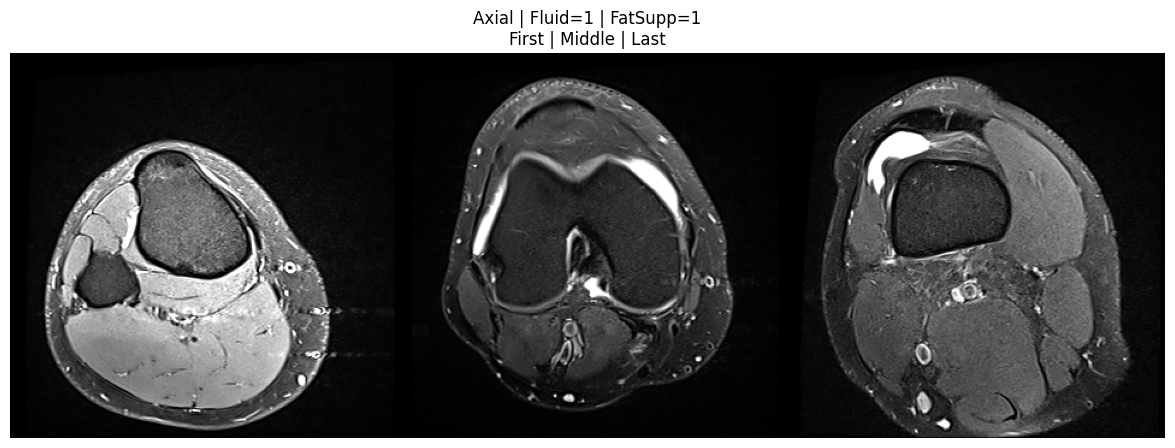

In [22]:
for _, row in study_series.iterrows():
    series_uid = str(row["SeriesInstanceUID"])
    files = sorted_dicom_files(study_path / series_uid)
    if not files:
        continue

    idxs = sorted(set([0, len(files)//2, len(files)-1]))
    imgs=[]
    for idx in idxs:
        img, _ = load_dicom_pixels(files[idx])
        imgs.append(normalize_for_display(img))

    max_h = max(x.shape[0] for x in imgs)
    padded=[]
    for img in imgs:
        h,w = img.shape[:2]
        if h < max_h:
            top=(max_h-h)//2
            bottom=max_h-h-top
            img=np.pad(img, ((top,bottom),(0,0)), mode="constant")
        padded.append(img)

    strip=np.concatenate(padded, axis=1)
    plt.figure(figsize=(15,5))
    plt.imshow(strip, cmap="gray")
    plt.axis("off")
    plt.title(f'{row["Anatomical_Plane"]} | Fluid={row["Fluid_Sensitive"]} | FatSupp={row["Fat_Suppression"]}\nFirst | Middle | Last')
    plt.show()

## 23. Pixel-intensity QC for the selected study

In [23]:
rows=[]
for _, row in study_series.iterrows():
    series_uid = str(row["SeriesInstanceUID"])
    files = sorted_dicom_files(study_path / series_uid)
    if not files:
        continue

    idxs = np.linspace(0, len(files)-1, min(5,len(files)), dtype=int)
    vals=[]
    for idx in idxs:
        img,_ = load_dicom_pixels(files[idx])
        vals.append(img.ravel())
    vals=np.concatenate(vals)

    rows.append({
        "SeriesInstanceUID": series_uid,
        "Plane": row["Anatomical_Plane"],
        "FluidSensitive": row["Fluid_Sensitive"],
        "FatSuppression": row["Fat_Suppression"],
        "SampledPixels": len(vals),
        "Min": float(np.min(vals)),
        "P1": float(np.percentile(vals,1)),
        "Median": float(np.median(vals)),
        "P99": float(np.percentile(vals,99)),
        "Max": float(np.max(vals)),
        "Mean": float(np.mean(vals)),
        "Std": float(np.std(vals)),
    })

display(pd.DataFrame(rows))

,SeriesInstanceUID,Plane,FluidSensitive,FatSuppression,SampledPixels,Min,P1,Median,P99,Max,Mean,Std
0,1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282,Sagittal,0,0,800000,0.0,0.0,68.0,632.0,1048.0,172.101044,191.352890
1,1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441,Coronal,0,0,737280,0.0,0.0,147.0,893.0,1341.0,221.615402,243.110107
2,1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198,Coronal,1,1,512000,0.0,0.0,38.0,378.0,639.0,62.951485,73.204453
3,1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429,Sagittal,1,1,512000,0.0,0.0,61.0,329.0,788.0,69.815643,71.303726
4,1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430,Axial,1,1,512000,0.0,0.0,18.0,334.0,685.0,59.362259,73.714394


## 24. DICOM geometry QC

In [24]:
rows=[]
for _, row in study_series.iterrows():
    series_uid = str(row["SeriesInstanceUID"])
    files = sorted_dicom_files(study_path / series_uid)
    shapes=set(); spacings=set(); orientations=set(); positions=[]

    for f in files:
        ds=pydicom.dcmread(str(f), stop_before_pixels=True)
        shapes.add((getattr(ds,"Rows",None), getattr(ds,"Columns",None)))
        ps=getattr(ds,"PixelSpacing",None)
        if ps is not None:
            spacings.add(tuple(round(float(x),6) for x in ps))
        orient=getattr(ds,"ImageOrientationPatient",None)
        if orient is not None:
            orientations.add(tuple(round(float(x),6) for x in orient))
        pos=slice_position_from_header(ds)
        if pos is not None:
            positions.append(round(float(pos),6))

    rows.append({
        "SeriesInstanceUID": series_uid,
        "Plane": row["Anatomical_Plane"],
        "Slices": len(files),
        "UniqueShapes": len(shapes),
        "UniquePixelSpacings": len(spacings),
        "UniqueOrientations": len(orientations),
        "SpatialPositionsAvailable": len(positions),
        "UniqueSpatialPositions": len(set(positions)),
        "DuplicateSpatialPositions": len(positions)-len(set(positions)),
    })

display(pd.DataFrame(rows))

,SeriesInstanceUID,Plane,Slices,UniqueShapes,UniquePixelSpacings,UniqueOrientations,SpatialPositionsAvailable,UniqueSpatialPositions,DuplicateSpatialPositions
0,1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282,Sagittal,36,1,1,1,36,36,0
1,1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441,Coronal,30,1,1,1,30,30,0
2,1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198,Coronal,30,1,1,1,30,30,0
3,1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429,Sagittal,36,1,1,1,36,36,0
4,1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430,Axial,32,1,1,1,32,32,0


## 25. Compare CSV metadata with folders on disk

In [25]:
csv_series=set(study_series["SeriesInstanceUID"].astype(str))
disk_series=set(p.name for p in study_path.iterdir() if p.is_dir())

print("Series in CSV:", len(csv_series))
print("Series on disk:", len(disk_series))
print("CSV series missing on disk:", csv_series-disk_series)
print("Unexpected disk folders:", disk_series-csv_series)

Series in CSV: 5
Series on disk: 5
CSV series missing on disk: set()
Unexpected disk folders: set()


# 26. Visible train/test structural comparison

The visible test data in a Kaggle code competition can be much smaller than the hidden scoring data. Never hard-code the number of test studies or series.

In [26]:
comparison=pd.DataFrame({
    "Split":["Train","Visible Test"],
    "Studies":[train["StudyInstanceUID"].nunique(), test["StudyInstanceUID"].nunique()],
    "Series":[train_series["SeriesInstanceUID"].nunique(), test_series["SeriesInstanceUID"].nunique()],
})
comparison["Series per study"] = comparison["Series"] / comparison["Studies"]
display(comparison)

,Split,Studies,Series,Series per study
0,Train,4407,24371,5.530066
1,Visible Test,3,15,5.000000


# 27. Optional dataset-wide slice-count scan

There are more than 24,000 training series. This scan is disabled by default because it may take time.
Set `RUN_FULL_SCAN = True` only when you are ready.

In [27]:
RUN_FULL_SCAN = True

if RUN_FULL_SCAN:
    rows=[]
    for i,row in train_series.iterrows():
        study_id=str(row["StudyInstanceUID"])
        series_id=str(row["SeriesInstanceUID"])
        p=DATA_DIR/"train_series"/study_id/series_id
        n_files=sum(1 for x in p.iterdir() if x.is_file()) if p.exists() else np.nan
        rows.append({
            "StudyInstanceUID": study_id,
            "SeriesInstanceUID": series_id,
            "Anatomical_Plane": row["Anatomical_Plane"],
            "Fluid_Sensitive": row["Fluid_Sensitive"],
            "Fat_Suppression": row["Fat_Suppression"],
            "n_files": n_files,
        })
        if (i+1)%2000==0:
            print(f"Processed {i+1:,} series")

    full_series_scan=pd.DataFrame(rows)
    display(full_series_scan["n_files"].describe().to_frame())
    display(full_series_scan.groupby("Anatomical_Plane")["n_files"].describe())
else:
    print("Skipped. Set RUN_FULL_SCAN = True to run the complete slice-count scan.")

Processed 2,000 series
Processed 4,000 series
Processed 6,000 series
Processed 8,000 series
Processed 10,000 series
Processed 12,000 series
Processed 14,000 series
Processed 16,000 series
Processed 18,000 series
Processed 20,000 series
Processed 22,000 series
Processed 24,000 series


,n_files
count,24371.000000
mean,33.608715
std,26.575246
min,11.000000
25%,25.000000
50%,30.000000
75%,34.000000
max,320.000000


,count,mean,std,min,25%,50%,75%,max
Anatomical_Plane,,,,,,,,
Axial,5898.0,39.820448,31.960938,12.0,28.0,32.0,38.0,254.0
Coronal,8609.0,28.269718,6.195147,11.0,25.0,30.0,32.0,80.0
Sagittal,9864.0,34.554238,32.433485,11.0,25.0,30.0,33.0,320.0


## 28. Automatic audit summary

In [28]:
n_train_studies=train["StudyInstanceUID"].nunique()
n_train_series=train_series["SeriesInstanceUID"].nunique()
n_gold=len(labeled)
n_unlabeled=(train["n_labels_available"]==0).sum()
planes=sorted(train_series["Anatomical_Plane"].dropna().astype(str).unique().tolist())

print("="*100)
print("RSNA KNEE DATASET — CURRENT AUDIT SUMMARY")
print("="*100)
print(f"Training studies:             {n_train_studies:,}")
print(f"Training MRI series:          {n_train_series:,}")
print(f"Average series per study:     {n_train_series/n_train_studies:.2f}")
print(f"Fully gold-labeled studies:   {n_gold:,}")
print(f"Completely unlabeled studies: {n_unlabeled:,}")
print(f"Gold-labeled percentage:      {100*n_gold/n_train_studies:.2f}%")
print("Anatomical planes:            ", ", ".join(planes))
print("\nSelected study:")
print(" UID:", study_uid)
print(" Series:", len(study_series))
print(" Positive labels:", positive_labels)

print("\nKey implications:")
print("1. Study-level prediction requires aggregation across multiple MRI series.")
print("2. Series metadata gives plane / fluid / fat-suppression information.")
print("3. Most training studies do not expose the 12 gold labels.")
print("4. Reports may be valuable for weak supervision, but target definitions must be understood first.")
print("5. Slice ordering should use DICOM spatial metadata when available.")
print("6. Hidden-test inference must be dynamic and must not assume only 3 studies.")

RSNA KNEE DATASET — CURRENT AUDIT SUMMARY
Training studies:             4,407
Training MRI series:          24,371
Average series per study:     5.53
Fully gold-labeled studies:   58
Completely unlabeled studies: 4,349
Gold-labeled percentage:      1.32%
Anatomical planes:             Axial, Coronal, Sagittal

Selected study:
 UID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
 Series: 5
 Positive labels: ['PF OA', 'Effusion']

Key implications:
1. Study-level prediction requires aggregation across multiple MRI series.
2. Series metadata gives plane / fluid / fat-suppression information.
3. Most training studies do not expose the 12 gold labels.
4. Reports may be valuable for weak supervision, but target definitions must be understood first.
5. Slice ordering should use DICOM spatial metadata when available.
6. Hidden-test inference must be dynamic and must not assume only 3 studies.


# 29. What to do next

After this notebook runs successfully, the next stage should be **dataset-wide EDA and label-definition research**, not final model training.

### Phase A — Dataset-wide MRI QC
- slice-count distribution,
- image resolution distribution,
- field strength and manufacturer,
- plane availability per study,
- missing/unusual series,
- intensity variation.

### Phase B — Report analysis
- language distribution,
- report length and structure,
- negation patterns,
- clinical terminology,
- mapping report findings to the 58 official gold labels.

### Phase C — Gold-label strategy
- exact target definitions,
- target correlations,
- whether the 58 labeled cases are enriched/curated,
- validation design with such a small gold set.

### Phase D — Baselines
1. report-derived label extraction / pseudo-label baseline,
2. MRI-only pretrained 2-D + MIL baseline,
3. weakly supervised MRI training,
4. multimodal teacher-student or fusion improvements.

**Do not lock the final architecture until the label definitions and dataset-wide QC are clear.**